In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ot
import pandas as pd
import seaborn

## Data Loading

In [2]:
df = pd.read_csv('INPUT/scRNAseq/theta_Zspace_annotation.csv').set_index('CellID')


ectoderm = ['Neuroectoderm/NMPs', 'Early neuroectoderm/NMPs' ]
endoderm = ['Endoderm', 'Early endoderm' ]
mesoderm = [ 'Cardiac mesoderm', 'Early cardiac mesoderm', 'Early somitic mesoderm','Somitic mesoderm' ]
primitive_tissues = ['Epiblast','Ectopic pluripotency', 'Primitive streak' , 'Naive pluripotency']
porcn_cluster = ['Wnt. inh. state']

# Create an empty dictionary to store the mappings
germ_layers = {}

# Populate the dictionary with the mappings
for item in ectoderm:
    germ_layers[item] = 'Neuroectoderm/NMPs'

for item in endoderm:
    germ_layers[item] = 'Endoderm'

for item in mesoderm:
    germ_layers[item] = 'Mesoderm'

for item in primitive_tissues:
    germ_layers[item] = 'Early tissues'

for item in porcn_cluster:
    germ_layers[item] = 'Wnt. inhibitor'

df['BIG_celltype'] = df['Cell type'].map(germ_layers)

df.columns

Index(['index', 'Dataset', 'dataset', 'Sample', 'Time', 'Condition',
       'Time_int', 'n_counts', 'log_counts', 'n_genes', 'mt_frac',
       'louvain_r2.5', 'Cell type', 'Color', 's_counts', 'u_counts',
       'percent_unspliced', 'total_counts', 'pca_theta', 'inferred_theta',
       'library_size', 'phase_bin', 'theta_1', 'theta_2', 'Z_space1',
       'Z_space2', 'BIG_celltype'],
      dtype='object')

In [5]:
# drop cells where Condition is 'cdk' or 'porcn' and time is <=72
df = df[~((df['Condition'].isin(['cdk', 'porcn'])) & (df['Time_int'] <= 72))]

## Rotation of z space for plotting purposes

In [ ]:


angle_deg = 30
theta = np.deg2rad(angle_deg)

# original coordinates
x = df['Z_space1'].values
y = df['Z_space2'].values

# rotation
x_rot = x * np.cos(theta) - y * np.sin(theta)
y_rot = x * np.sin(theta) + y * np.cos(theta)

df['Z_space1'] = x_rot
df['Z_space2'] = y_rot


## Z-space with cell type

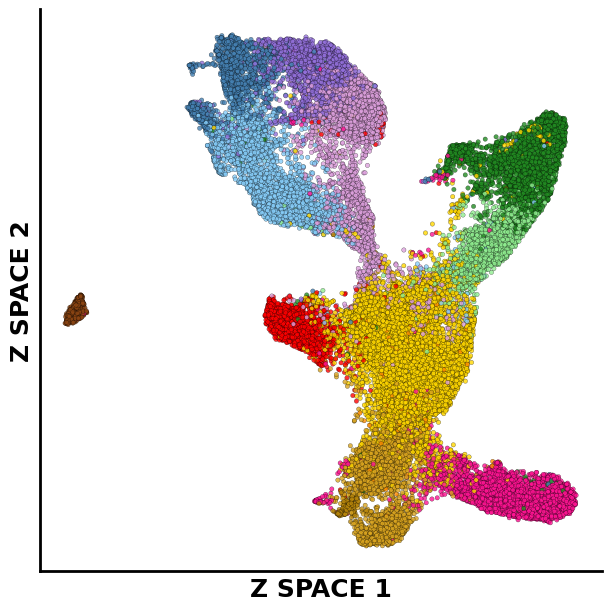

In [12]:
# --- 0) Filter data (using df instead of adata.obs) ---
mask = (df['louvain_r2.5'] != '26') & (df['louvain_r2.5'] != '28')
df = df.loc[mask].copy()


# --- 1) Define desired legend order ---
legend_order = [
    'Naive pluripotency', 'Exiting pluripotency', 'Epiblast', 'Primitive streak',
    'Early cardiac mesoderm', 'Cardiac mesoderm',
    'Early somitic mesoderm', 'Somitic mesoderm',
    'Early endoderm', 'Endoderm',
    'Early neuroectoderm/NMPs', 'Neuroectoderm/NMPs', 'Wnt. inh. state'
]

# --- 2) Build color map from df ---
unique_cell_types = df['Cell type'].unique()
cmap = {
    ctype: df.loc[df['Cell type'] == ctype, 'Color'].iloc[0]
    for ctype in unique_cell_types
}

# Keep only legend entries that actually exist
legend_types_present = [ct for ct in legend_order if ct in cmap]

# --- 3) Randomise draw order ---
N = len(df)
perm = np.random.permutation(N)

X = df.loc[df.index[perm], 'Z_space1'].values
Y = df.loc[df.index[perm], 'Z_space2'].values
colors = df.loc[df.index[perm], 'Color'].values

# --- 4) Main embedding figure (6x6) ---
fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)

ax.scatter(
    X, Y,
    c=colors,
    s=10,
    alpha=0.8,
    edgecolor="black",
    linewidth=0.2
)

ax.set_xlabel("Z SPACE 1", fontsize=18, fontweight="bold")
ax.set_ylabel("Z SPACE 2", fontsize=18, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_linewidth(2)

ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(labelsize=10)

fig.savefig(
    "FIGURES/zspace_celltype.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()




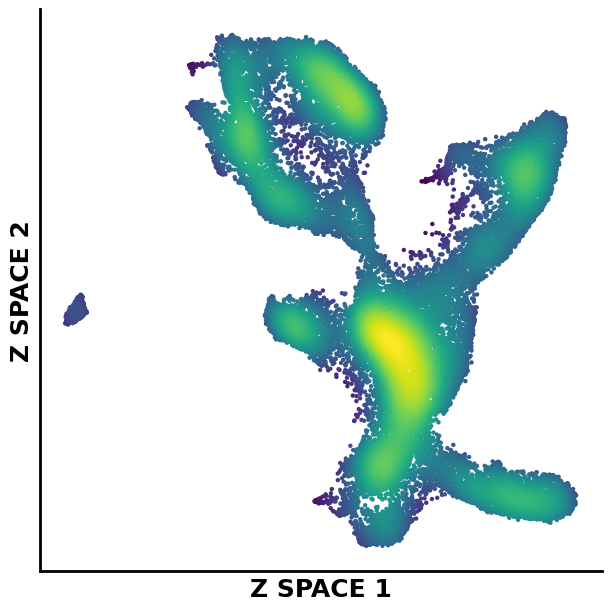

In [14]:
from scipy.stats import gaussian_kde

# --- Use same randomized coordinates ---
xy = np.vstack([X, Y])
kde = gaussian_kde(xy, bw_method=0.15)
density = kde(xy)

# Sort by density so dense regions are on top
idx = density.argsort()
X_d, Y_d, D_d = X[idx], Y[idx], density[idx]

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)

ax.scatter(
    X_d, Y_d,
    c=D_d,
    s=10,
    cmap="viridis",
    edgecolor="none"
)

ax.set_xlabel("Z SPACE 1", fontsize=18, fontweight="bold")
ax.set_ylabel("Z SPACE 2", fontsize=18, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_linewidth(2)

ax.set_xticks([])
ax.set_yticks([])

fig.savefig(
    "FIGURES/zspace_density_kde.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()

## Cell densities in Zspace

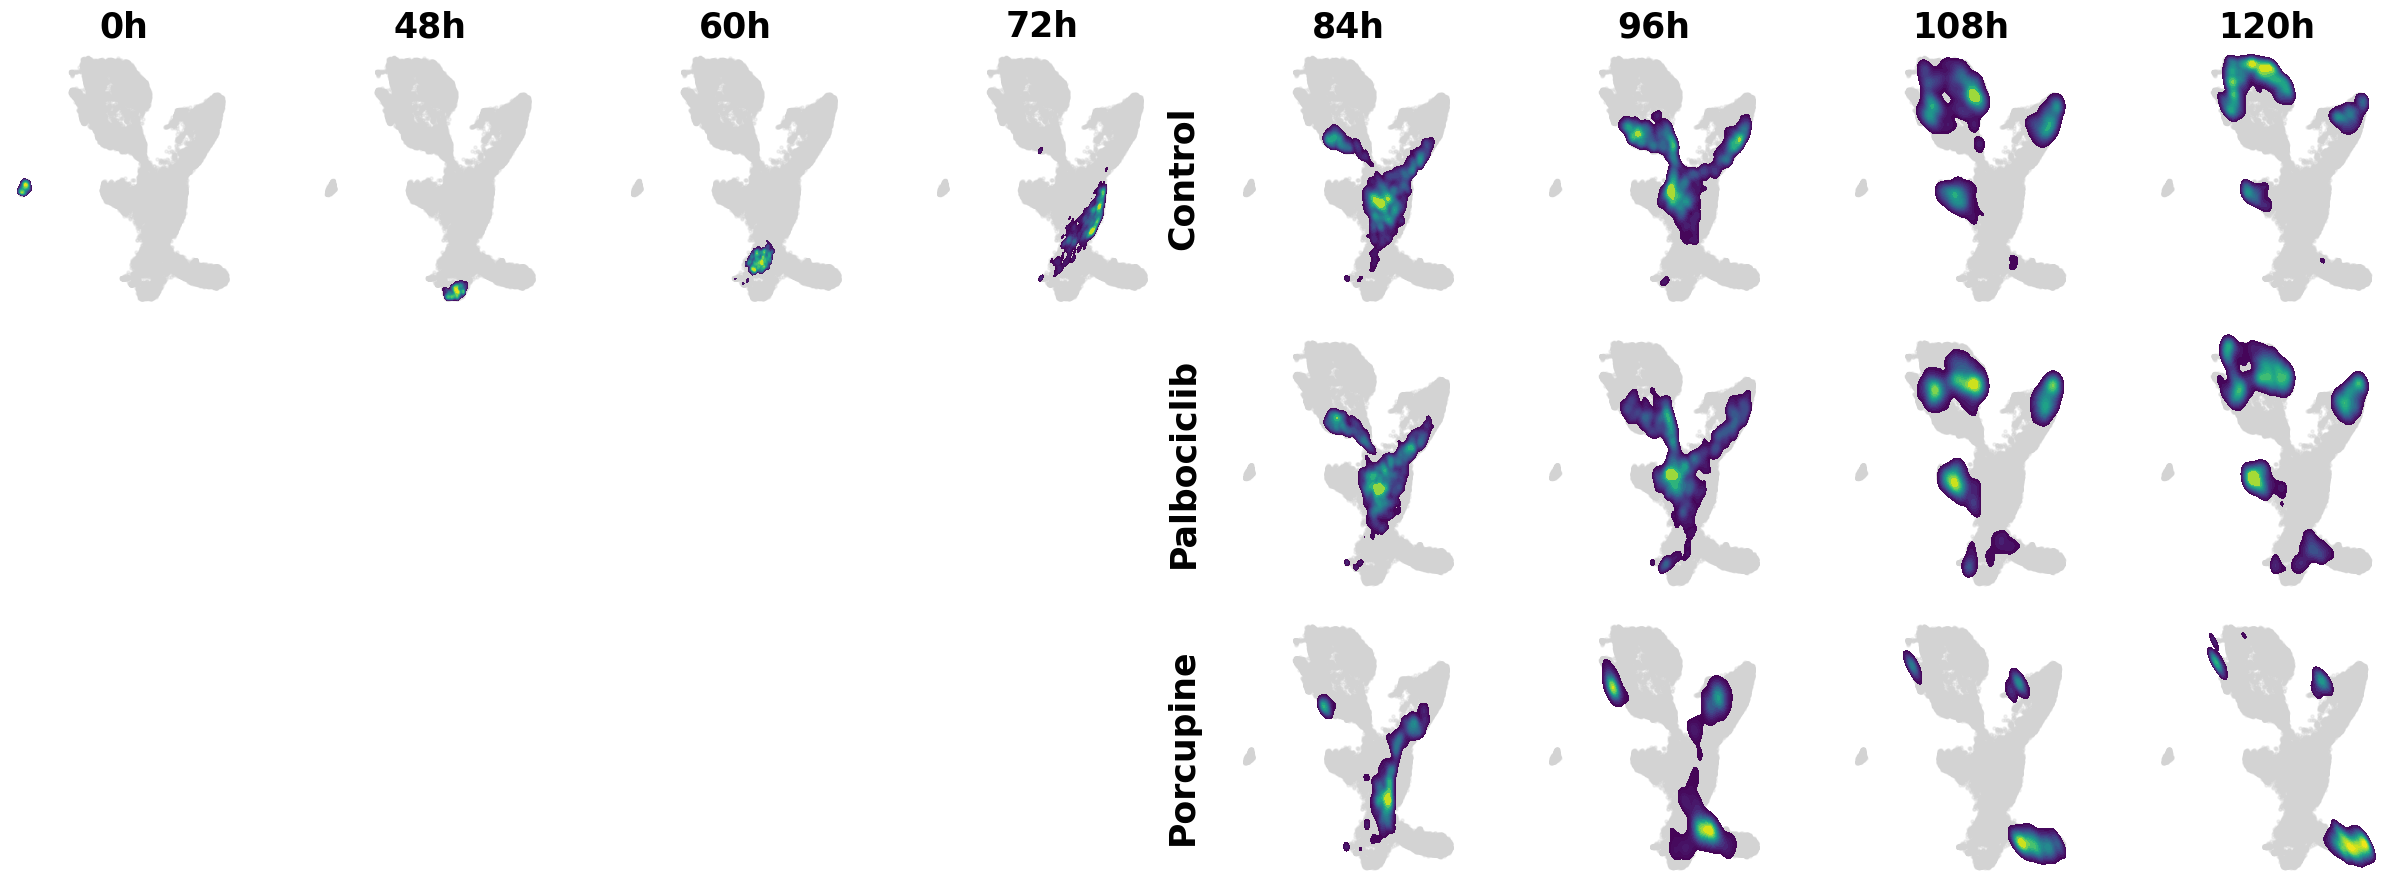

In [ ]:





df['Time'] = pd.to_numeric(df['Time_int'], errors='coerce')

# Define conditions and time points
conditions = ['ctrl', 'cdk', 'porcn']
time_points = [0, 48, 60, 72, 84, 96, 108, 120]
condition_labels = {'ctrl': 'Control', 'cdk': 'Palbociclib', 'porcn': 'Porcupine'}


x_min, x_max = df['Z_space1'].min(), df['Z_space1'].max()
y_min, y_max = df['Z_space2'].min(), df['Z_space2'].max()
padding_x = (x_max - x_min) * 0.05
padding_y = (y_max - y_min) * 0.05
x_min, x_max = x_min - padding_x, x_max + padding_x
y_min, y_max = y_min - padding_y, y_max + padding_y

# Create subplot grid
n_rows = len(conditions)
n_cols = len(time_points)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows), sharex=True, sharey=True)

for i, cond in enumerate(conditions):
    for j, time in enumerate(time_points):
        ax = axes[i, j] if n_rows > 1 else axes[j]
        subset = df[(df['Condition'] == cond) & (df['Time'] == time)]
        
        # Conditional background scatter:
        if cond == 'ctrl' or time >= 84:
            ax.scatter(df['Z_space1'], df['Z_space2'], color='lightgrey', alpha=0.3, s=5)

        # Plot KDE if data is present
        if not subset.empty:
            sns.kdeplot(
                x=subset['Z_space1'],
                y=subset['Z_space2'],
                fill=True,
                cmap='viridis',
                thresh=0.1,
                levels=20,
                alpha=1,
                bw_adjust=0.3,
                ax=ax
            )

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.axis('off')
        
        if i == 0:
            ax.set_title(f'{time}h', fontsize=25, fontweight='bold')

# Add y-labels at the middle row
for i, cond in enumerate(conditions):
    ax_middle = axes[i, n_cols // 2] if n_cols > 1 else axes[i]
    ax_middle.text(
        x_min - (x_max - x_min) * 0.15,  
        (y_min + y_max) / 2,             
        condition_labels[cond],
        va='center', ha='right', rotation=90,
        fontsize=25, fontweight='bold'
    )

plt.tight_layout()



plt.show()


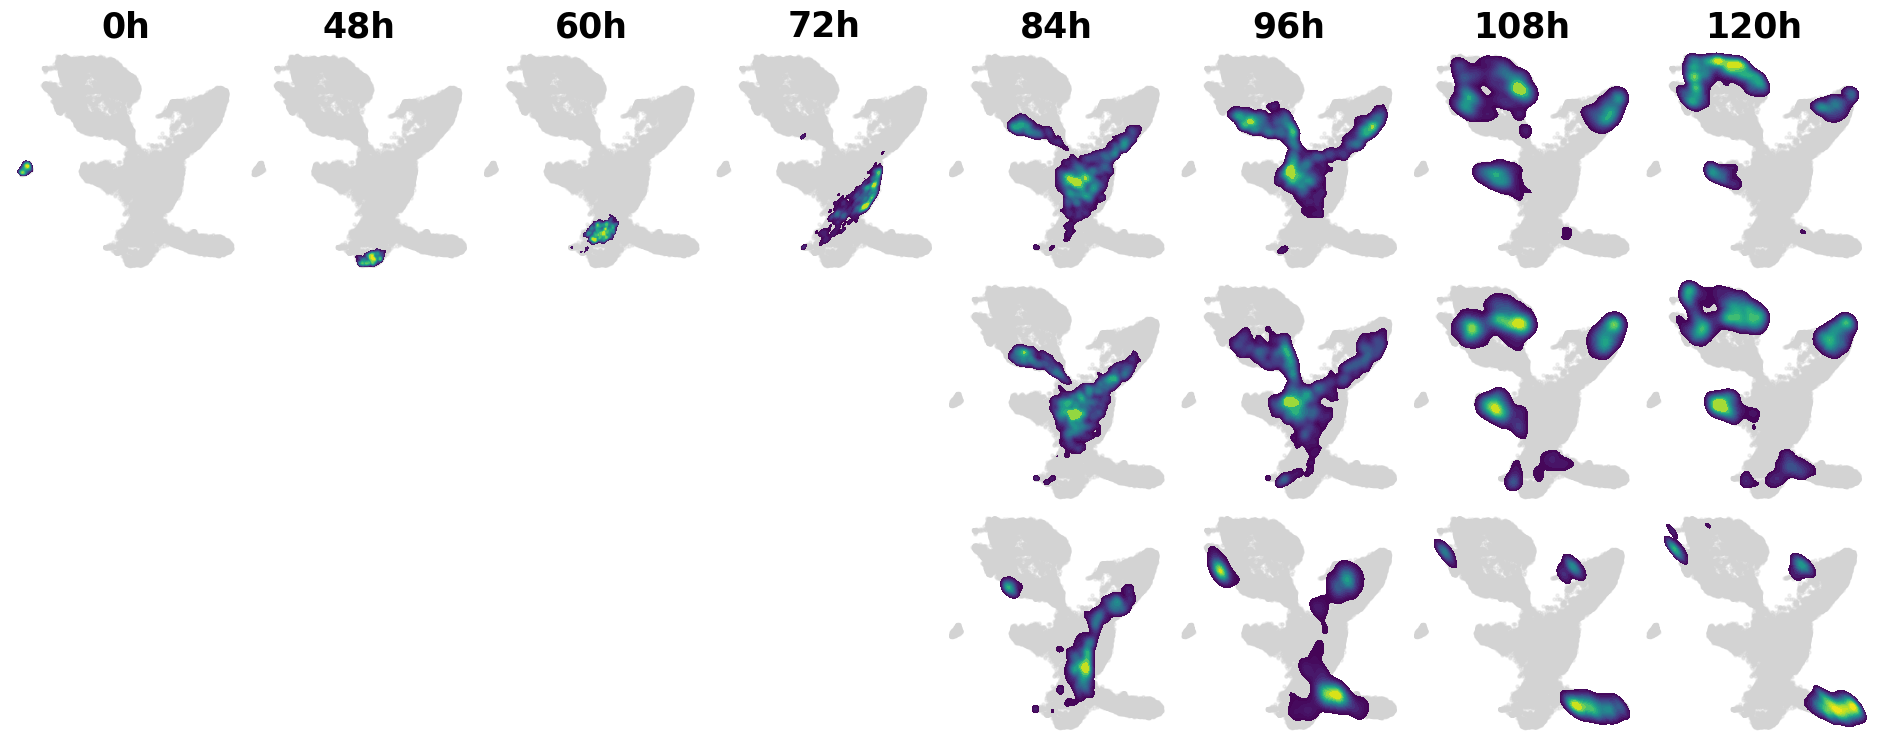

In [ ]:
# Remove blank space from axis

# --- parameters ---
conditions = ['ctrl', 'cdk', 'porcn']
time_points = [0, 48, 60, 72, 84, 96, 108, 120]
condition_labels = {'ctrl': 'Control', 'cdk': 'CDK4/6 inh.', 'porcn': 'Wnt inh.'}

#remove from plot
gap_lo, gap_hi = -8, -5
gap_w = gap_hi - gap_lo

def squash_gap(x):
    x = np.asarray(x, dtype=float)
    keep = ~((x >= gap_lo) & (x < gap_hi))    
    x_kept = x[keep]
    x_kept = np.where(x_kept >= gap_hi, x_kept - gap_w, x_kept)  
    return x_kept, keep

x_squashed, keep_mask_all = squash_gap(df['Z_space1'].values)
df = df.loc[keep_mask_all].copy()
df['Z_space1_squash'] = x_squashed

# --- figure limits (use squashed x) ---
x_min, x_max = df['Z_space1_squash'].min(), df['Z_space1_squash'].max()
y_min, y_max = df['Z_space2'].min(), df['Z_space2'].max()
padding_x = (x_max - x_min) * 0.05
padding_y = (y_max - y_min) * 0.05
x_min, x_max = x_min - padding_x, x_max + padding_x
y_min, y_max = y_min - padding_y, y_max + padding_y

# --- subplot grid (no spacing) ---
n_rows = len(conditions)
n_cols = len(time_points)
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(3 * n_cols, 3 * n_rows),
    sharex=True, sharey=True,
    gridspec_kw={'wspace': 0, 'hspace': 0}
)
fig.subplots_adjust(wspace=0.1, hspace=0.1)

for i, cond in enumerate(conditions):
    for j, time in enumerate(time_points):
        ax = axes[i, j] if n_rows > 1 else axes[j]
        
        # Subset for this condition/time (after squashing)
        subset = df[(df['Condition'] == cond) & (df['Time'] == time)]
        
        if cond == 'ctrl' or time >= 84:
            ax.scatter(df['Z_space1_squash'], df['Z_space2'], color='lightgrey', alpha=0.3, s=5)

        # KDE on squashed x
        if not subset.empty:
            sns.kdeplot(
                x=subset['Z_space1_squash'],
                y=subset['Z_space2'],
                fill=True,
                cmap='viridis',
                thresh=0.1,
                levels=20,
                alpha=1,
                bw_adjust=0.3,
                ax=ax
            )

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.axis('off')

        if i == 0:
            ax.set_title(f'{time}h', fontsize=25, fontweight='bold', pad=6)


fig.savefig(
    "FIGURES/Densities_time_condition.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


## Create trajectories with optimal transport

/home/mleonard/miniconda3/envs/ot_env/lib/python3.10/site-packages/ot/lp/_network_simplex.py:332: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)
/home/mleonard/miniconda3/envs/ot_env/lib/python3.10/site-packages/ot/lp/_network_simplex.py:332: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)
/home/mleonard/miniconda3/envs/ot_env/lib/python3.10/site-packages/ot/lp/_network_simplex.py:332: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)
/home/mleonard/miniconda3/envs/ot_env/lib/python3.10/site-packages/ot/lp/_network_simplex.py:332: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)
/home/mleonard/miniconda3/envs/ot_env/lib/python3.10/site-packages/ot/lp/_network_simplex.py:332

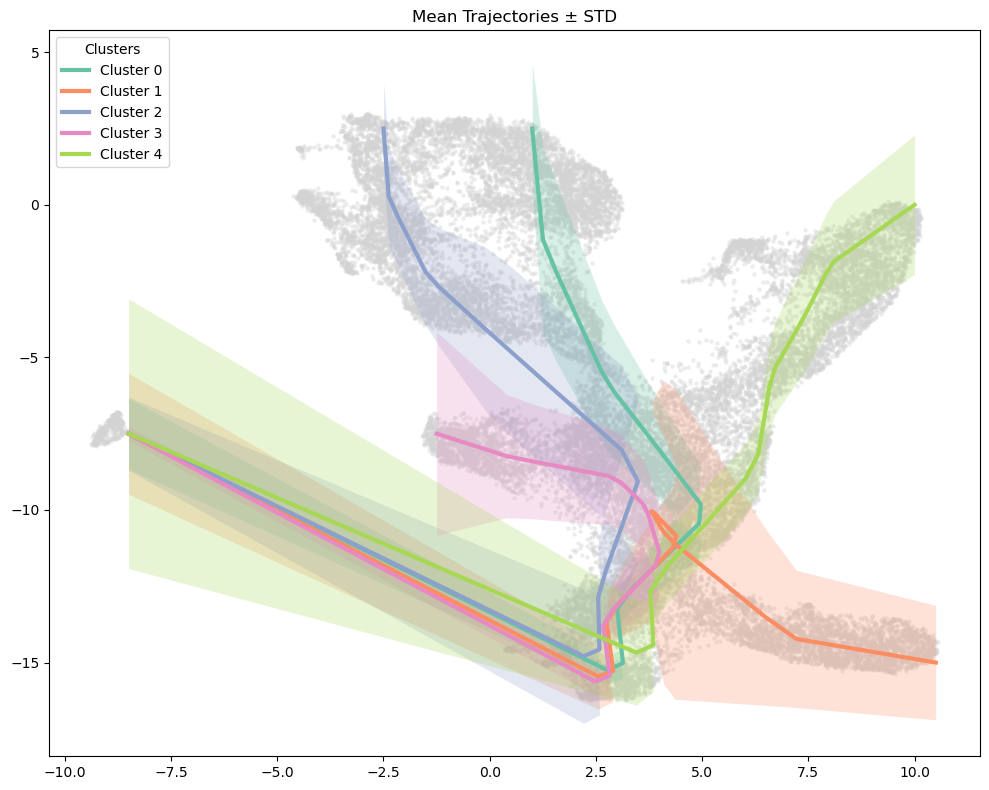

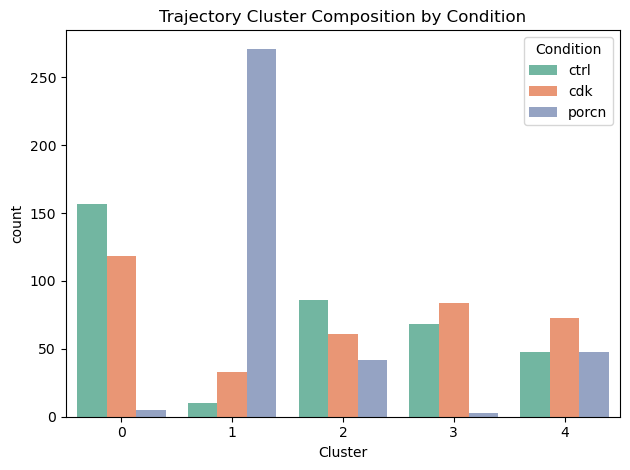

In [ ]:

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

np.random.seed(0)

# -------------------------------
# 1. Duplicate shared timepoints
# -------------------------------
shared_times = [0, 48, 60, 72]
conditions = ['ctrl', 'cdk', 'porcn']

df_shared = df[
    (df['Time_int'].isin(shared_times)) &
    (df['Condition'] == 'ctrl')
]

df_aug = pd.concat(
    [df_shared.assign(Condition=cond) for cond in conditions] +
    [df[df['Condition'] == cond] for cond in conditions],
    ignore_index=True
)

# -------------------------------
# 2. Track trajectories with lineage rules
# -------------------------------
N = 1000
start_cells = df_shared[df_shared['Time_int'] == 0][['Z_space1', 'Z_space2']].to_numpy()
start_indices = np.random.choice(len(start_cells), size=min(N, len(start_cells)), replace=False)
start_positions = [start_cells[i] for i in start_indices]

tracked_dict = {cond: [[pos] for pos in start_positions] for cond in conditions}

LINEAGE_PENALTY = 1e8
EARLY_LABEL = "Early tissues"   

for cond in conditions:
    cond_df = df_aug[df_aug['Condition'] == cond]
    times = sorted(cond_df['Time_int'].unique())

    for t1, t2 in zip(times[:-1], times[1:]):

        df1 = cond_df[cond_df['Time_int'] == t1]
        df2 = cond_df[cond_df['Time_int'] == t2]

        if len(df1) == 0 or len(df2) == 0:
            continue

        X1 = df1[['Z_space1', 'Z_space2']].to_numpy()
        X2 = df2[['Z_space1', 'Z_space2']].to_numpy()

        L1 = df1['BIG_celltype'].to_numpy()
        L2 = df2['BIG_celltype'].to_numpy()

        a = np.ones(len(X1)) / len(X1)
        b = np.ones(len(X2)) / len(X2)

        # Base cost
        M = ot.dist(X1, X2) ** 2

        # Lineage constraint:
        #   - Early tissues: unrestricted
        #   - Otherwise: must stay in same lineage
        for i in range(len(L1)):
            if L1[i] == EARLY_LABEL:
                continue  # allow transitions to all lineages
            mismatch = L2 != L1[i]
            M[i, mismatch] = LINEAGE_PENALTY

        G = ot.emd(a, b, M)

        # Advance trajectories
        for i, traj in enumerate(tracked_dict[cond]):
            last = traj[-1]
            idx = np.argmin(np.sum((X1 - last) ** 2, axis=1))
            jdx = np.argmax(G[idx])
            traj.append(X2[jdx])

# -------------------------------
# 3. Flatten trajectories
# -------------------------------
all_trajs = []
all_conds = []

expected_len = len(shared_times) + 4 

for cond, trajs in tracked_dict.items():
    for traj in trajs:
        if len(traj) == expected_len:
            all_trajs.append(np.array(traj).flatten())
            all_conds.append(cond)

all_trajs = np.stack(all_trajs)

traj_pca = PCA(n_components=3, random_state=1).fit_transform(all_trajs)
labels = KMeans(n_clusters=5, random_state=1).fit_predict(traj_pca)

# -------------------------------
# 4. Plot trajectories
# -------------------------------
from scipy.interpolate import make_interp_spline

# -------------------------------
# 4. Plot mean ± std trajectories
# -------------------------------
CLUSTER_ENDPOINTS = {
    3: (-1.25, -7.5),
    4: (10.0, 0.0),
    2: (-2.5, 2.5),
    0: (1, 2.5),
    1: (10.5, -15.0),
}


fig, ax = plt.subplots(figsize=(10, 8))

# ---- Grey background Z-space ----
ax.scatter(
    df['Z_space1'],
    df['Z_space2'],
    color='lightgrey',
    s=5,
    alpha=0.3,
    zorder=0
)

unique_clusters = np.unique(labels)
palette = sns.color_palette("Set2", n_colors=len(unique_clusters))

timepoints = np.arange(expected_len)
smoothed_mean_trajs = {}
for cl, col in zip(unique_clusters, palette):

    cluster_trajs = all_trajs[labels == cl]
    cluster_trajs = cluster_trajs.reshape(len(cluster_trajs), expected_len, 2)

    mean_traj = cluster_trajs.mean(axis=0)
    std_traj = cluster_trajs.std(axis=0)

    # -------------------------------
    # Initial and final points
    # -------------------------------
    mean_traj[0, 0] = -8.5
    mean_traj[0, 1] = -7.5
    
    if cl in CLUSTER_ENDPOINTS:
        mean_traj[-1, 0] = CLUSTER_ENDPOINTS[cl][0]
        mean_traj[-1, 1] = CLUSTER_ENDPOINTS[cl][1]

    # ---- Smooth mean trajectory ----
    t_smooth = np.linspace(timepoints.min(), timepoints.max(), 30)

    spline_x = make_interp_spline(timepoints, mean_traj[:, 0], k=1)
    spline_y = make_interp_spline(timepoints, mean_traj[:, 1], k=1)

    x_smooth = spline_x(t_smooth)
    y_smooth = spline_y(t_smooth)

    ax.plot(
        x_smooth,
        y_smooth,
        color=col,
        lw=3,
        label=f"Cluster {cl}",
        zorder=3
    )

    # ---- Std band ----
    std_mag = np.linalg.norm(std_traj, axis=1)
    std_spline = make_interp_spline(timepoints, std_mag, k=1)
    std_smooth = std_spline(t_smooth)

    ax.fill_between(
        x_smooth,
        y_smooth - std_smooth,
        y_smooth + std_smooth,
        color=col,
        alpha=0.25,
        linewidth=0,
        zorder=2
    )
    smoothed_mean_trajs[cl] = np.vstack([x_smooth, y_smooth]).T


ax.set_title("Mean Trajectories ± STD")
ax.legend(title="Clusters")
plt.tight_layout()
plt.show()


# -------------------------------
# 5. Cluster composition
# -------------------------------
cluster_df = pd.DataFrame({
    'Condition': all_conds,
    'Cluster': labels
})

sns.countplot(
    data=cluster_df,
    x='Cluster',
    hue='Condition',
    palette='Set2'
)

plt.title("Trajectory Cluster Composition by Condition")
plt.tight_layout()
plt.show()


In [22]:
n_clusters = 5

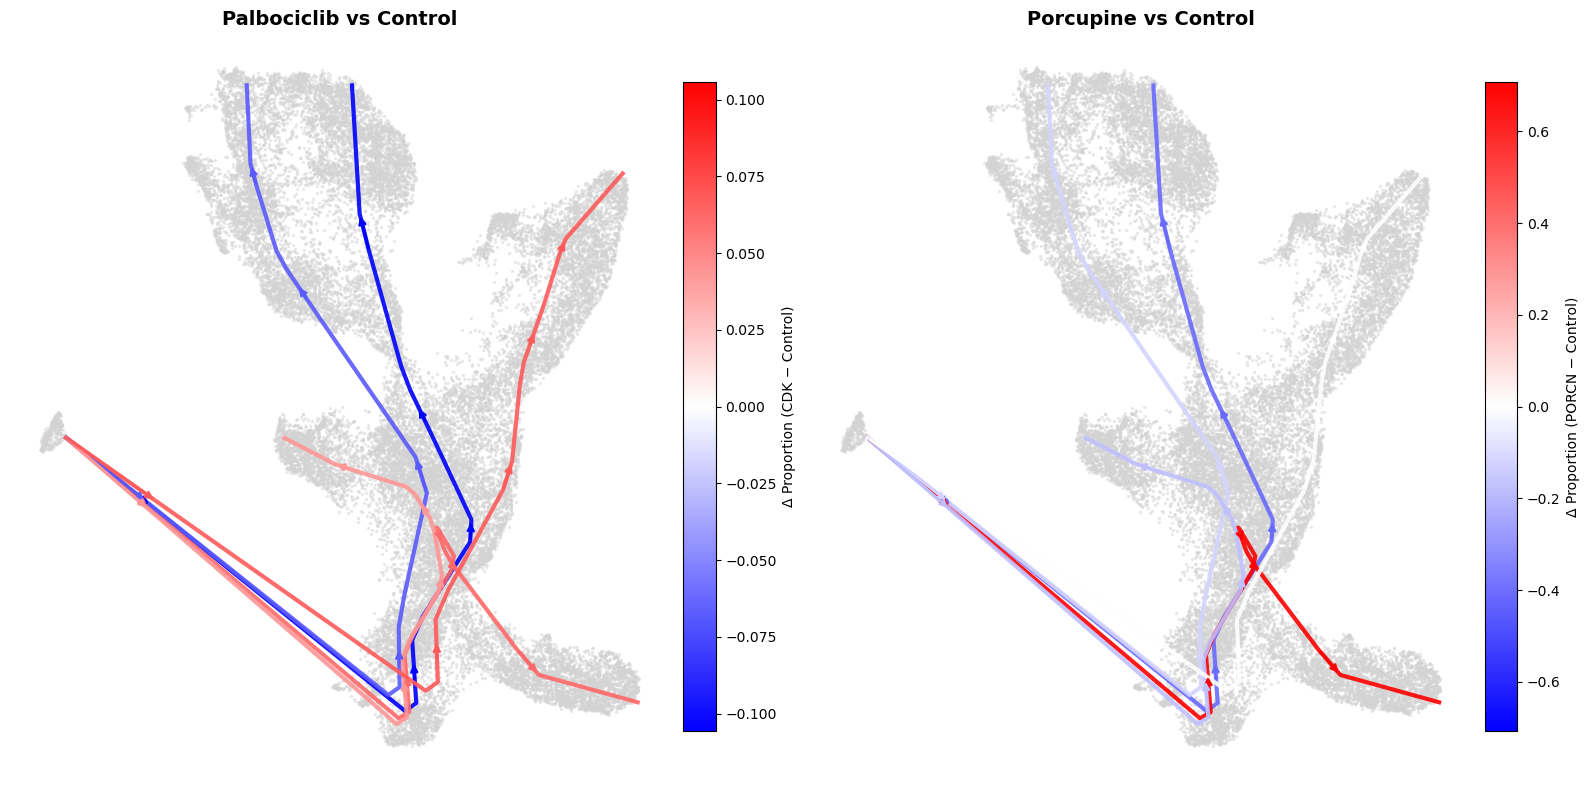

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from scipy.interpolate import make_interp_spline, interp1d

# 1. Compute cluster proportions per condition
cluster_df = pd.DataFrame({'Condition': all_conds, 'Cluster': labels})
cluster_counts = cluster_df.groupby(['Condition', 'Cluster']).size().unstack(fill_value=0)
cluster_props = cluster_counts.div(cluster_counts.sum(axis=1), axis=0)

# 2. Compute control proportions and deltas
ctrl_props = cluster_props.loc['ctrl']
cdk_delta = cluster_props.loc['cdk'] - ctrl_props
porcn_delta = cluster_props.loc['porcn'] - ctrl_props


# 4. Background UMAP points
umap_points = df[['Z_space1', 'Z_space2']].to_numpy()

# 5. Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
condition_deltas = {'cdk': cdk_delta, 'porcn': porcn_delta}
titles = {'cdk': 'Palbociclib vs Control', 'porcn': 'Porcupine vs Control'}

for ax, cond in zip(axes, ['cdk', 'porcn']):
    ax.scatter(umap_points[:, 0], umap_points[:, 1], color='lightgrey', s=2, alpha=0.4)
    
    deltas = condition_deltas[cond]
    vmax = max(abs(deltas.max()), abs(deltas.min()))
    norm = plt.Normalize(vmin=-vmax, vmax=vmax)
    cmap = plt.cm.bwr
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    
    for cl in range(n_clusters):
        traj = smoothed_mean_trajs[cl]  
        color = cmap(norm(deltas[cl]))

        ax.plot(traj[:, 0], traj[:, 1], color=color, linewidth=3, alpha=0.9)

        arrow_freq = max(1, len(traj) // 5)
        for i in range(0, len(traj) - 1, arrow_freq):
            start, end = traj[i], traj[i + 1]
            ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color=color, lw=2))
    
    ax.set_title(titles[cond], fontweight='bold', fontsize=14)
    ax.axis('off')
    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.046, pad=0.02)
    cbar.set_label(f"Δ Proportion ({cond.upper()} − Control)", fontsize=10)

plt.tight_layout()
 # Save high-res PNG with transparent background
output_filename = "trajectory_shift_comparison.png"

plt.show()


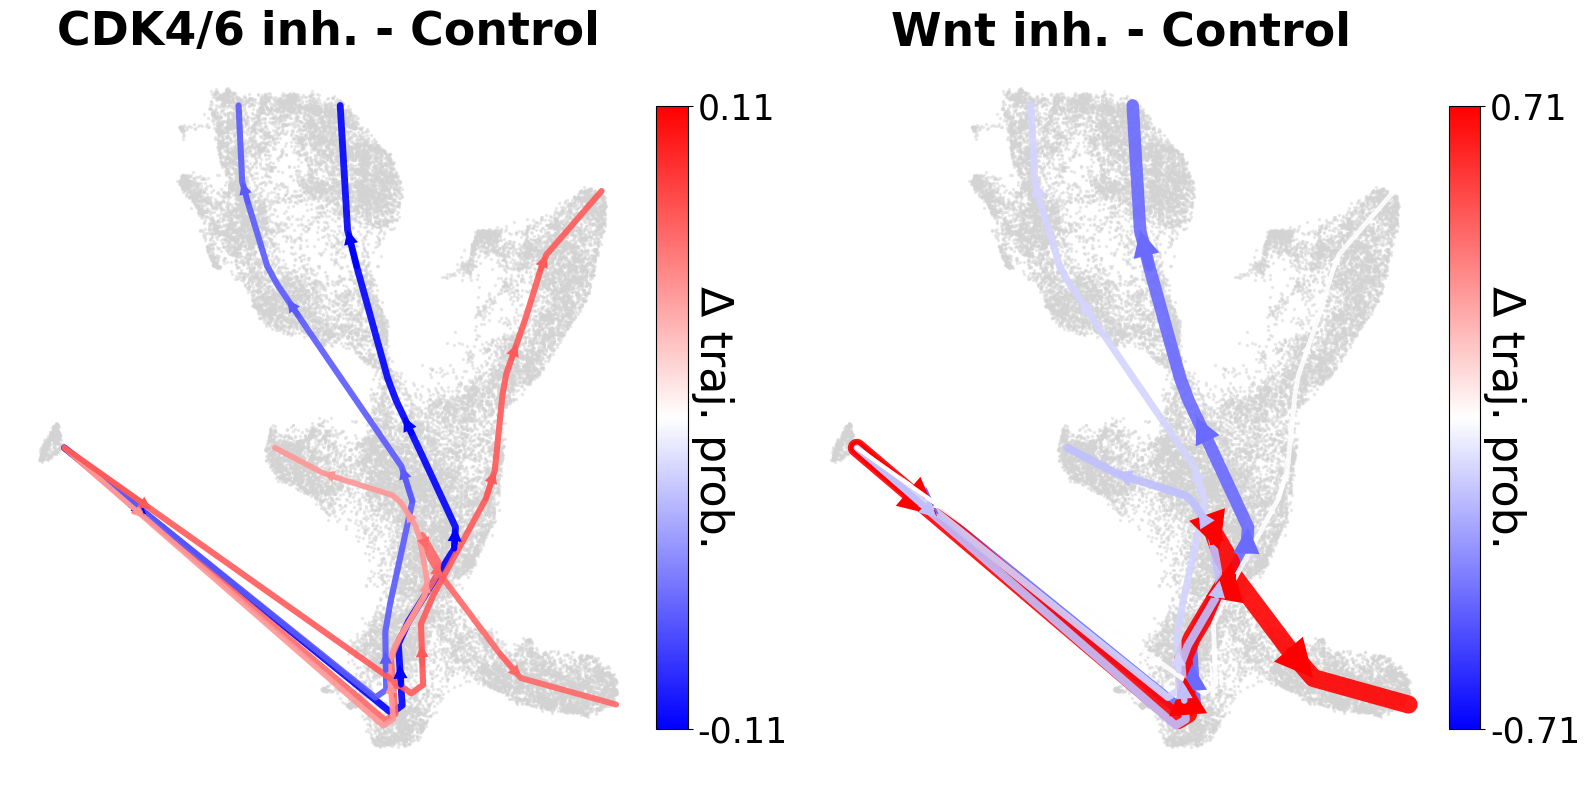

In [ ]:
# --- helpers 
min_lw, max_lw = 3.5, 13.0       # line width range 
min_ms, max_ms = 6.0, 28.0       # arrowhead size range
min_aw, max_aw = 3.0, 10.0       # arrow shaft linewidth range

def scale_by_delta(d, vmax, lo, hi):
    if not np.isfinite(d) or not np.isfinite(vmax) or vmax == 0:
        return lo
    return float(lo + (hi - lo) * (abs(d) / vmax))

# Collect deltas
condition_deltas = {'cdk': cdk_delta, 'porcn': porcn_delta}
titles = {'cdk': 'CDK4/6 inh. - Control', 'porcn': 'Wnt inh. - Control'}

# --- GLOBAL vmax ---
all_deltas = pd.concat([cdk_delta.rename('cdk'), porcn_delta.rename('porcn')], axis=1)
global_vmax = float(np.nanmax(np.abs(all_deltas.values))) if all_deltas.size else 0.0

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)

for ax, cond in zip(axes, ['cdk', 'porcn']):
    # Background UMAP points
    ax.scatter(umap_points[:, 0], umap_points[:, 1], color='lightgrey', s=2, alpha=0.4)

  
    if isinstance(deltas, pd.Series):
        deltas = deltas.reindex(range(n_clusters), fill_value=np.nan)

    # --- per-panel color scaling  ---
    local_vmax = float(np.nanmax(np.abs(deltas.values))) if len(deltas) else 0.0
    norm = plt.Normalize(vmin=-local_vmax, vmax=local_vmax)
    cmap = plt.cm.bwr
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    for cl in range(n_clusters):
        traj = smoothed_mean_trajs[cl]  
        d = float(deltas.iloc[cl] if isinstance(deltas, pd.Series) else deltas[cl])

        # color scaled per panel
        color = cmap(norm(d))

        # thickness and arrow sizes scaled by GLOBAL |Δ|
        lw = scale_by_delta(d, global_vmax, min_lw, max_lw)  # trajectory line width
        aw = scale_by_delta(d, global_vmax, min_aw, max_aw)  # arrow shaft linewidth
        ms = scale_by_delta(d, global_vmax, min_ms, max_ms)  # arrowhead size

        # trajectory
        ax.plot(
            traj[:, 0], traj[:, 1],
            color=color, linewidth=lw, alpha=0.9, solid_capstyle='round'
        )

        # direction arrows along trajectory
        arrow_freq = max(1, len(traj) // 5)
        for i in range(0, len(traj) - 1, arrow_freq):
            start, end = traj[i], traj[i + 1]
            ax.annotate(
                '',
                xy=end, xytext=start,
                arrowprops=dict(
                    arrowstyle='-|>',
                    lw=aw,
                    color=color,
                    mutation_scale=ms,
                    shrinkA=0, shrinkB=0,
                    joinstyle='miter', capstyle='round'
                )
            )

    ax.set_title(titles[cond], fontweight='bold', fontsize=33)
    ax.axis('off')

   
    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.046, pad=0.015)

    if local_vmax > 0:
        ticks = [-local_vmax, local_vmax]
        ticklabels = [f"{-local_vmax:.2f}", f"{local_vmax:.2f}"]
    else:
        ticks = [0.0]
        ticklabels = ["0.00"]

    cbar.set_ticks(ticks)
    cbar.set_ticklabels(ticklabels)
    cbar.ax.tick_params(labelsize=25)

   
    cbar.set_label("", rotation=270)
    cbar.ax.yaxis.set_ticks_position('right')
    cbar.ax.yaxis.set_label_position('right')
    cbar.ax.text(
        1.1, 0.5, "Δ traj. prob.",
        rotation=270, va='center', ha='left',
        transform=cbar.ax.transAxes, fontsize=32
    )

plt.tight_layout()

fig.savefig(
    "FIGURES/Trajectories_probabilites.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


## Pseudotime analysis

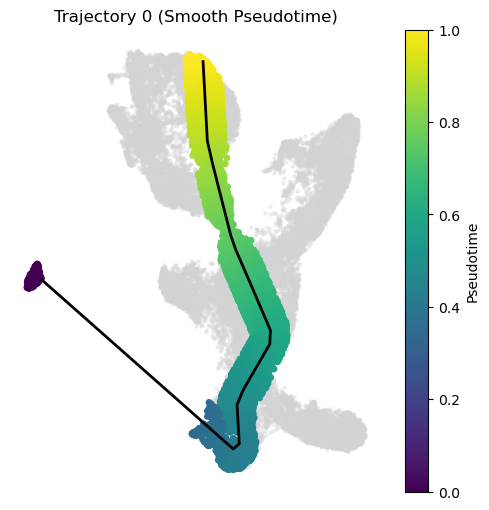

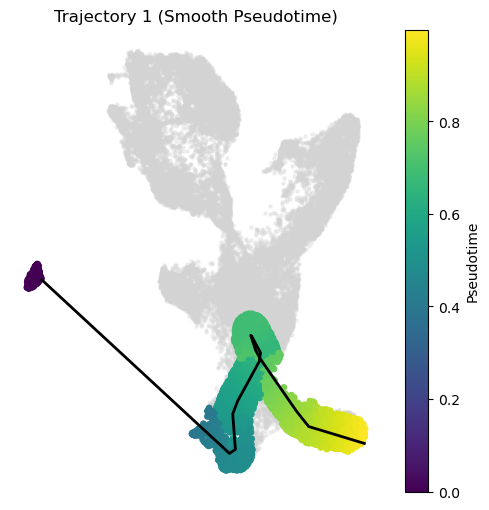

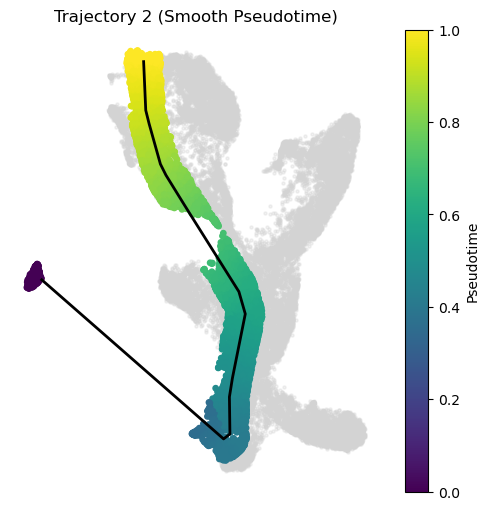

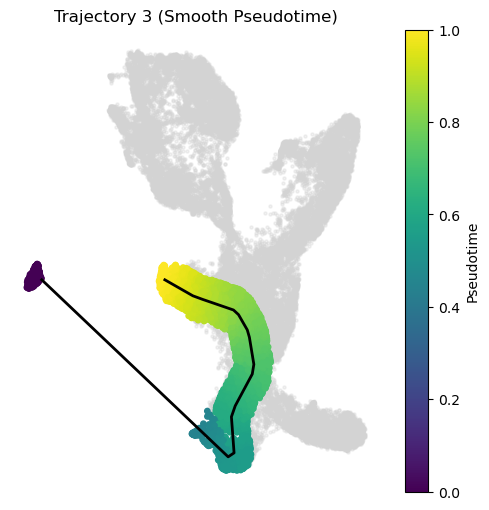

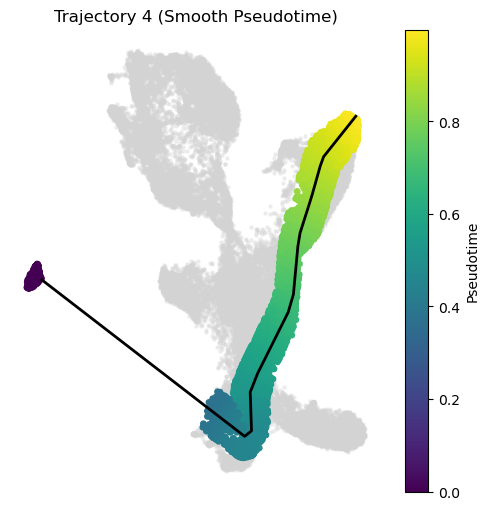

In [25]:
rep_trajectories = list(smoothed_mean_trajs.values())

from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import numpy as np

wideness = 1
cell_coords = df[['Z_space1', 'Z_space2']].to_numpy()
umap_points = df[['Z_space1', 'Z_space2']].to_numpy()

cell_associations = []
cell_pseudotime_dict = []

for cell in cell_coords:
    associated_clusters = []
    pseudo_times = {}
    
    for cl, traj in enumerate(rep_trajectories):
        min_dist = np.inf
        best_pseudo = None
        
        # Loop through each segment of the trajectory
        for i in range(len(traj) - 1):
            p1, p2 = traj[i], traj[i+1]
            v = p2 - p1
            u = cell - p1
            t = np.dot(u, v) / np.dot(v, v)
            t = np.clip(t, 0, 1)  # projection fraction along the segment
            proj = p1 + t * v
            dist = np.linalg.norm(cell - proj)
            
            if dist < min_dist:
                min_dist = dist
                # Compute cumulative length up to p1, plus distance along v
                segment_lengths = np.linalg.norm(np.diff(traj, axis=0), axis=1)
                cumdist = np.insert(np.cumsum(segment_lengths), 0, 0)
                total_length = cumdist[-1]
                length_up_to_proj = cumdist[i] + t * segment_lengths[i]
                best_pseudo = length_up_to_proj / total_length if total_length > 0 else 0
        
        if min_dist <= wideness:
            associated_clusters.append(cl)
            pseudo_times[cl] = best_pseudo
    
    cell_associations.append(associated_clusters)
    cell_pseudotime_dict.append(pseudo_times)

df['AssignedClusters'] = cell_associations
df['PseudotimeDict'] = cell_pseudotime_dict

# Visualise smoother pseudotime per trajectory
n_clusters = len(rep_trajectories)
for cl in range(n_clusters):
    plt.figure(figsize=(6, 6))
    plt.scatter(umap_points[:, 0], umap_points[:, 1], color='lightgrey', s=5, alpha=0.3)
    cells_in_cl = df[df['AssignedClusters'].apply(lambda x: cl in x)]
    pseudo = cells_in_cl['PseudotimeDict'].apply(lambda d: d.get(cl, np.nan))
    plt.scatter(cells_in_cl['Z_space1'], cells_in_cl['Z_space2'], c=pseudo, cmap='viridis', s=15)
    plt.plot(rep_trajectories[cl][:, 0], rep_trajectories[cl][:, 1], color='black', linewidth=2)
    plt.colorbar(label='Pseudotime')
    plt.title(f'Trajectory {cl} (Smooth Pseudotime)')
    plt.axis('off')
    plt.show()


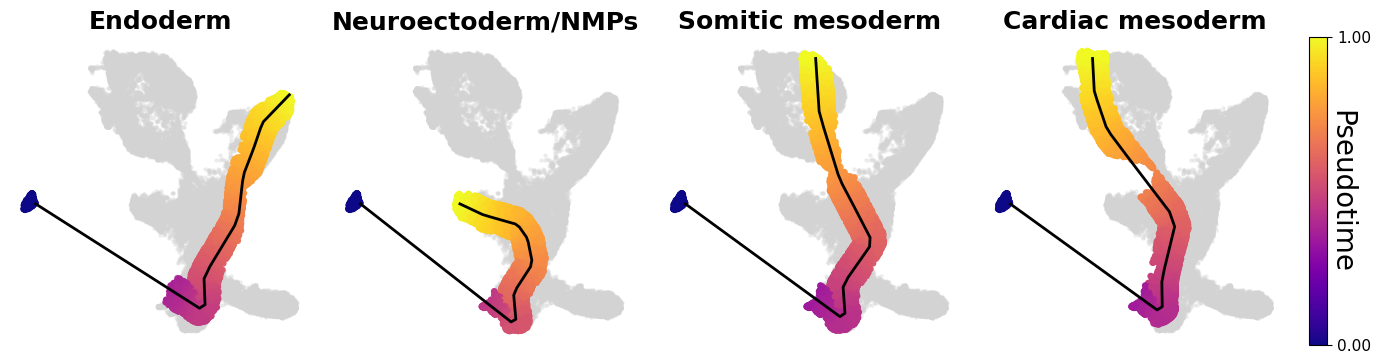

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

cluster_order = [ 4, 3, 0, 2]  # Removed cluster 1 (PORCN)
cluster_names = {0: 'Somitic mesoderm', 1: 'Wnt. inh. state', 2: 'Cardiac mesoderm', 3: 'Neuroectoderm/NMPs', 4: 'Endoderm'}

# Set up the figure 
n_clusters = len(cluster_order)
fig = plt.figure(figsize=(4 * n_clusters + 1, 4))  
gs = gridspec.GridSpec(1, n_clusters + 1, width_ratios=[1]*n_clusters + [0.06], wspace=0.1)

axes = [fig.add_subplot(gs[0, i]) for i in range(n_clusters)]
cax = fig.add_subplot(gs[0, -1])  

sc_last = None  
for idx, cl in enumerate(cluster_order):
    ax = axes[idx]
    
    # Plot background
    ax.scatter(umap_points[:, 0], umap_points[:, 1], color='lightgrey', s=5, alpha=0.3)
    
    # Plot cluster cells
    cells_in_cl = df[df['AssignedClusters'].apply(lambda x: cl in x)]
    pseudo = cells_in_cl['PseudotimeDict'].apply(lambda d: d.get(cl, np.nan))
    sc = ax.scatter(
        cells_in_cl['Z_space1'], cells_in_cl['Z_space2'],
        c=pseudo, cmap='plasma', s=15
    )
    sc_last = sc  

    # Plot trajectory
    ax.plot(rep_trajectories[cl][:, 0], rep_trajectories[cl][:, 1], color='black', linewidth=2)
    

    ax.set_title(cluster_names[cl], fontsize=18, fontweight='bold', pad=6)
    ax.axis('off')

cbar = fig.colorbar(sc_last, cax=cax)


vmin = float(sc_last.norm.vmin) if sc_last.norm.vmin is not None else np.nanmin(sc_last.get_array())
vmax = float(sc_last.norm.vmax) if sc_last.norm.vmax is not None else np.nanmax(sc_last.get_array())
cbar.set_ticks([vmin, vmax])
cbar.set_ticklabels([f"{vmin:.2f}", f"{vmax:.2f}"])
cbar.ax.tick_params(labelsize=11)


cbar.set_label("")

cbar.ax.yaxis.set_ticks_position('right')
cbar.ax.yaxis.set_label_position('right')

label_x = 1.005  
cbar.ax.text(
    label_x, 0.5, "Pseudotime",
    rotation=270, va='center', ha='left',
    transform=cbar.ax.transAxes,
    fontsize=20, fontweight='normal'
)

fig.savefig(
    "FIGURES/Trajectories_pseudotime.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


/tmp/ipykernel_1745735/3816282402.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1745735/3816282402.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1745735/3816282402.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1745735/3816282402.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


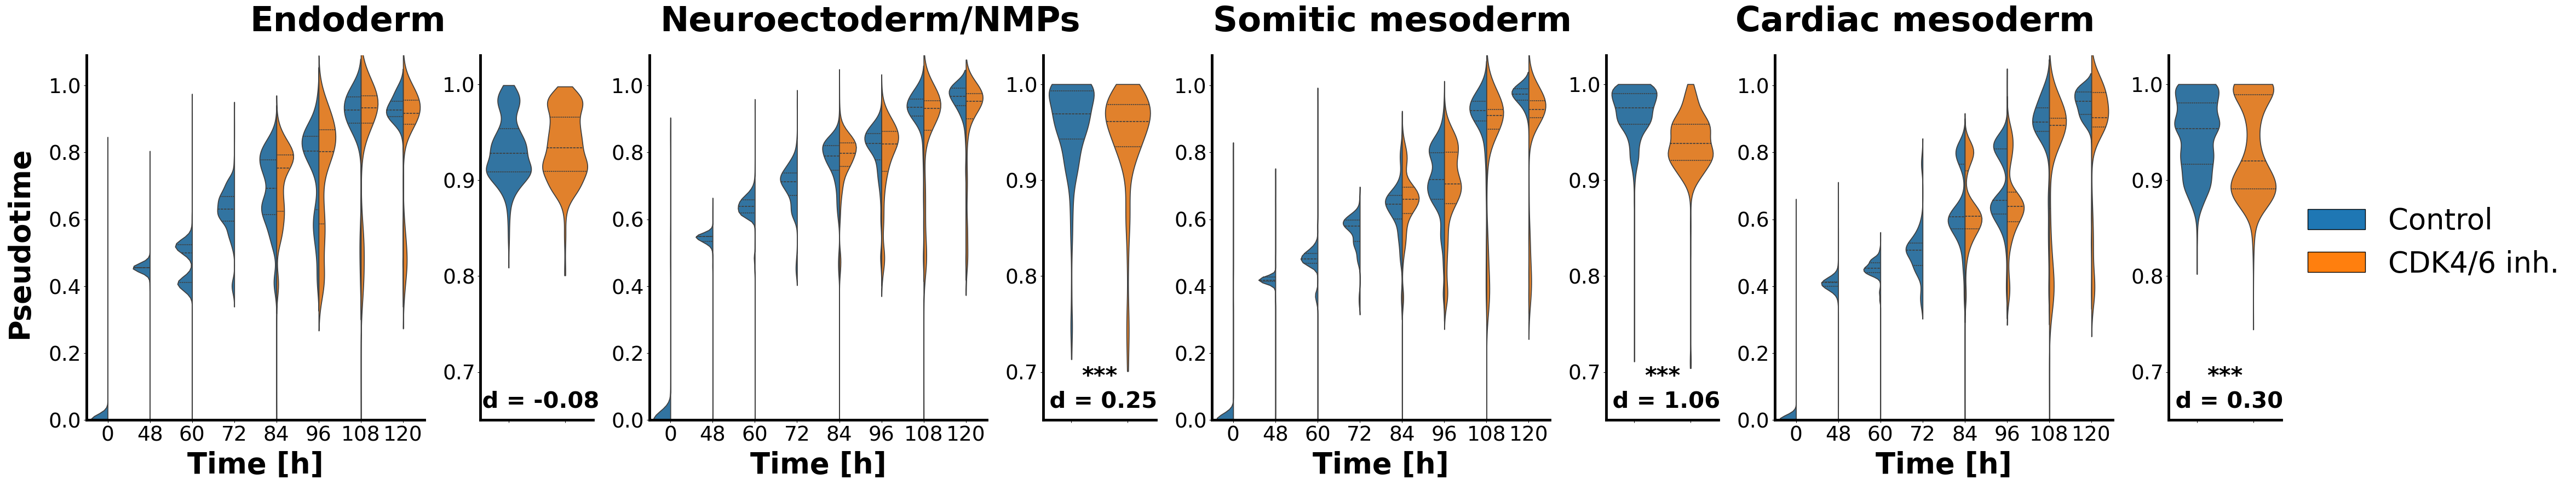

In [ ]:
# === Parameters ===
cluster_order = [4, 3, 0, 2]  
cluster_names = {
    0: 'Somitic mesoderm',
    1: 'Wnt. inh. state',
    2: 'Cardiac mesoderm',
    3: 'Neuroectoderm/NMPs',
    4: 'Endoderm'
}

custom_palette = {'ctrl': 'tab:blue', 'cdk': 'tab:orange'}

BIG_TITLE_FS = 45
AXLABEL_FS = 38
TICK_FS = 27
STAR_FS = 30
SPINE_LW = 3.5

# --- build long-form data ---
plot_data = []
for cl in cluster_order:
    data_cl = df[df['AssignedClusters'].apply(lambda x: cl in x)]
    data_cl = data_cl[data_cl['Condition'].isin(['ctrl', 'cdk'])]
    for _, row in data_cl.iterrows():
        pseudo = row['PseudotimeDict'].get(cl, np.nan)
        if not np.isnan(pseudo):
            plot_data.append({
                'Trajectory': cluster_names[cl],
                'Time_int': row['Time_int'],
                'Pseudotime': pseudo,
                'Condition': row['Condition']
            })

plot_df = pd.DataFrame(plot_data)
n_clusters = len(cluster_order)

# --- figure ---
fig = plt.figure(figsize=(12 * n_clusters, 9))
width_ratios = [3, 1] * n_clusters
gs = gridspec.GridSpec(1, 2 * n_clusters, width_ratios=width_ratios, wspace=0.25)

left_axes = []
right_axes = []
pair_axes = []

legend_handles = [
    Patch(facecolor=custom_palette['ctrl'], edgecolor='black', label='Control'),
    Patch(facecolor=custom_palette['cdk'], edgecolor='black', label='CDK4/6 inh.')
]

for idx, cl in enumerate(cluster_order):
    cl_name = cluster_names[cl]
    data_cl = plot_df[plot_df['Trajectory'] == cl_name]

    # === Left: time-resolved split violins ===
    ax_main = fig.add_subplot(gs[0, 2 * idx])
    sns.violinplot(
        data=data_cl,
        x='Time_int',
        y='Pseudotime',
        hue='Condition',
        hue_order=['ctrl', 'cdk'],
        split=True,
        inner='quartile',
        palette=custom_palette,
        density_norm='width',
        ax=ax_main,
        legend=False
    )

    ax_main.set_xlabel('Time [h]', fontsize=AXLABEL_FS, fontweight='bold', labelpad=8)
    ax_main.set_ylabel('')
    ax_main.set_ylim(0.0, 1.09)
    ax_main.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax_main.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    ax_main.tick_params(axis='x', labelsize=TICK_FS)
    ax_main.tick_params(axis='y', labelsize=TICK_FS)
    ax_main.spines['right'].set_visible(False)
    ax_main.spines['top'].set_visible(False)
    ax_main.spines['left'].set_linewidth(SPINE_LW)
    ax_main.spines['bottom'].set_linewidth(SPINE_LW)

    left_axes.append(ax_main)

    # === Right: 120h top-tail (Pseudotime > 0.7) ===
    data_120h = data_cl[data_cl['Time_int'] == 120]
    data_top = data_120h[data_120h['Pseudotime'] > 0.7]

    ax_top = fig.add_subplot(gs[0, 2 * idx + 1])
    sns.violinplot(
        data=data_top,
        x='Condition',
        y='Pseudotime',
        order=['ctrl', 'cdk'],      
        palette=custom_palette,
        inner='quartile',
        density_norm='width',
        cut=0,
        width=0.8,
        ax=ax_top,
        legend=False
    )

    ax_top.set_xlabel('')
    ax_top.set_xticklabels([])
    ax_top.tick_params(axis='x', labelbottom=False)
    ax_top.set_ylabel('')
    ax_top.set_ylim(0.65, 1.03)
    ax_top.set_yticks(np.arange(0.7, 1.0, 0.1))
    ax_top.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    ax_top.tick_params(axis='y', labelsize=TICK_FS)
    ax_top.spines['right'].set_visible(False)
    ax_top.spines['top'].set_visible(False)
    ax_top.spines['left'].set_linewidth(SPINE_LW)
    ax_top.spines['bottom'].set_linewidth(SPINE_LW)

    # --- stats ---
    ctrl_vals_top = data_top[data_top['Condition'] == 'ctrl']['Pseudotime']
    cdk_vals_top = data_top[data_top['Condition'] == 'cdk']['Pseudotime']

    if len(ctrl_vals_top) > 1 and len(cdk_vals_top) > 1:
        t_stat, p_val = ttest_ind(ctrl_vals_top, cdk_vals_top, equal_var=False)
        mean_diff = ctrl_vals_top.mean() - cdk_vals_top.mean()
        pooled_std = ((ctrl_vals_top.std()**2 + cdk_vals_top.std()**2) / 2) ** 0.5
        cohens_d = mean_diff / pooled_std if pooled_std > 0 else np.nan

        stars = ''
        if p_val < 0.001:
            stars = '***'
        elif p_val < 0.01:
            stars = '**'
        elif p_val < 0.05:
            stars = '*'

        anno = stars + (f'\n d = {cohens_d:.2f}' if np.isfinite(cohens_d) else '')
        ax_top.text(
            0.5, 0.15, anno,
            ha='center', va='top',
            fontsize=STAR_FS, fontweight='bold',
            transform=ax_top.transAxes
        )

    right_axes.append(ax_top)
    pair_axes.append((ax_main, ax_top, cl_name))

# --- centered titles over each pair ---
fig.canvas.draw()
for axL, axR, title in pair_axes:
    posL = axL.get_position()
    posR = axR.get_position()
    mid_x = 0.5 * (posL.x0 + posR.x1)
    top_y = max(posL.y1, posR.y1)
    fig.text(mid_x, top_y + 0.035, title,
             ha='center', va='bottom',
             fontsize=BIG_TITLE_FS, fontweight='bold')

# --- common y-label and legend ---
leftmost_x0 = min(ax.get_position().x0 for ax in left_axes)
rightmost_x1 = max(ax.get_position().x1 for ax in right_axes)

fig.text(
    leftmost_x0 - 0.03, 0.5, 'Pseudotime',
    fontsize=AXLABEL_FS, fontweight='bold',
    rotation=90, va='center', ha='right'
)

fig.legend(
    handles=legend_handles,
    labels=['Control', 'CDK4/6 inh.'],
    loc='center left',
    bbox_to_anchor=(rightmost_x1 + 0.05, 0.5),
    frameon=False,
    fontsize=AXLABEL_FS
)

fig.subplots_adjust(
    left=leftmost_x0 - 0.01,
    right=rightmost_x1 + 0.05,
    bottom=0.14,
    top=0.88,
    wspace=0.25
)

fig.savefig(
    "FIGURES/Pseudotime_distribution_percelltype.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


/tmp/ipykernel_1745735/3773356625.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_1745735/3773356625.py:9: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


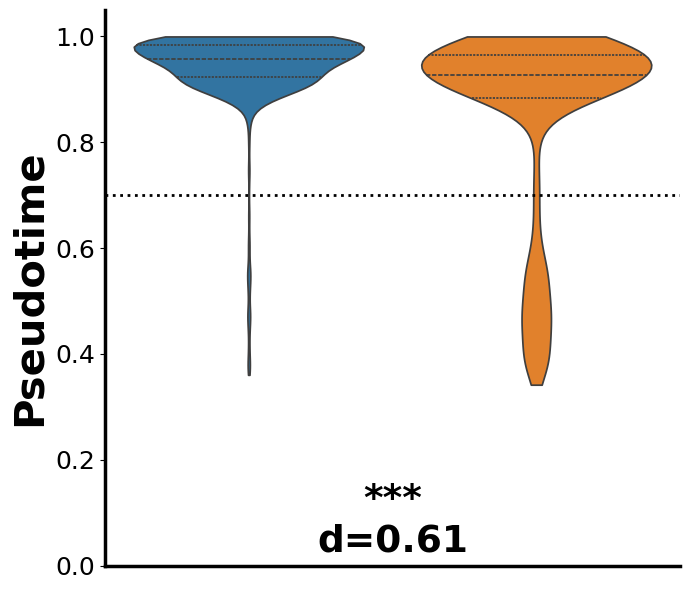

In [ ]:


fig2, ax2 = plt.subplots(figsize=(7, 6))

# Filter 120h cells
data_all_120h = plot_df[plot_df['Time_int'] == 120]

# Plot violin for ctrl vs cdk
sns.violinplot(
    data=data_all_120h,
    x='Condition',
    y='Pseudotime',
    order=['ctrl', 'cdk'],   
    palette=custom_palette,
    inner='quartile',
    scale='width',
    cut=0,
    width=0.8,
    ax=ax2
)

# T-test across all trajectories
ctrl_vals_all = data_all_120h[data_all_120h['Condition'] == 'ctrl']['Pseudotime']
cdk_vals_all = data_all_120h[data_all_120h['Condition'] == 'cdk']['Pseudotime']

if len(ctrl_vals_all) > 1 and len(cdk_vals_all) > 1:
    t_stat, p_val = ttest_ind(ctrl_vals_all, cdk_vals_all, equal_var=False)

    mean_diff = ctrl_vals_all.mean() - cdk_vals_all.mean()
    pooled_std = ((ctrl_vals_all.std() ** 2 + cdk_vals_all.std() ** 2) / 2) ** 0.5
    cohens_d = mean_diff / pooled_std if pooled_std > 0 else np.nan

    annotation = ''
    if p_val < 0.001:
        annotation += '***'
    elif p_val < 0.01:
        annotation += '**'
    elif p_val < 0.05:
        annotation += '*'
    annotation += f'\nd={cohens_d:.2f}'

    ax2.text(
        0.5, 0.15, annotation,
        ha='center', va='top',
        fontsize=27, fontweight='bold',
        transform=ax2.transAxes
    )

# Labels & ticks
ax2.set_ylabel('Pseudotime', fontsize=30, fontweight='bold')
ax2.set_xlabel('')
ax2.set_xticklabels([])
ax2.tick_params(axis='x', length=0)

# Y-axis limits and ticks
ax2.set_ylim(0.0, 1.05)
ax2.set_yticks(np.arange(0.0, 1.01, 0.2))
ax2.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax2.tick_params(axis='y', labelsize=18)

# Reference line
ax2.axhline(0.7, linestyle=':', linewidth=2, color='black', zorder=3)

# Clean spines
ax2.spines['right'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.spines['left'].set_linewidth(2.5)
ax2.spines['bottom'].set_linewidth(2.5)
ax2.yaxis.set_ticks_position('left')
ax2.xaxis.set_ticks_position('bottom')

plt.tight_layout()

# Save
fig2.savefig(
    "FIGURES/Pseudotime_distribution_global.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


## Merge trajectories (For subsequent analysis)

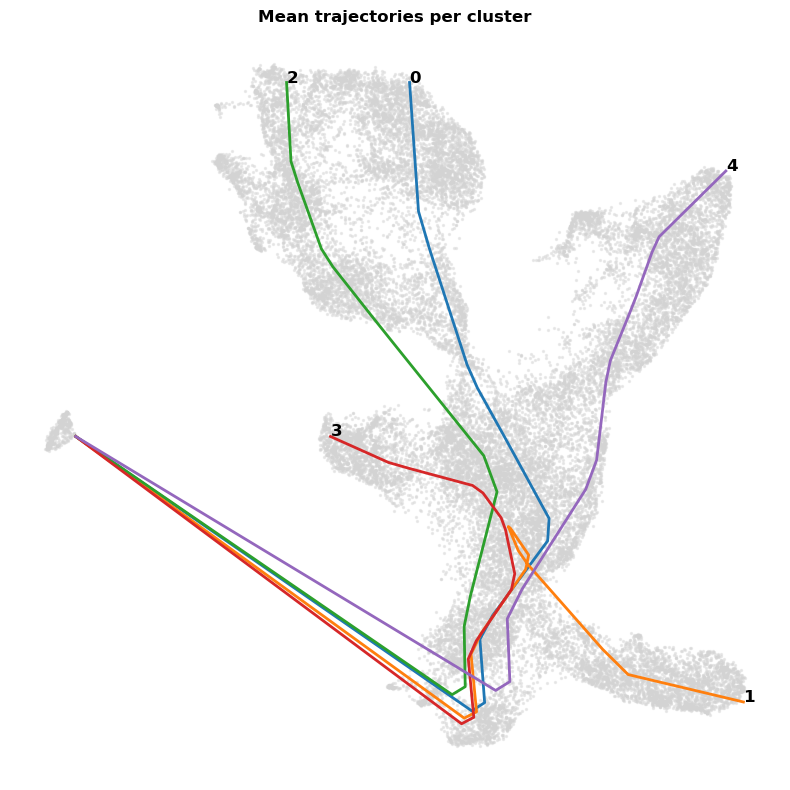

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))

# background UMAP
ax.scatter(
    umap_points[:, 0],
    umap_points[:, 1],
    color="lightgrey",
    s=2,
    alpha=0.4
)

for cl in range(len(smoothed_mean_trajs)):
    traj = np.asarray(smoothed_mean_trajs[cl])

 
    if traj.ndim == 1:
        traj = traj.reshape(-1, 2)
    if traj.ndim != 2 or traj.shape[1] != 2:
        print(f"Skipping cluster {cl}, shape = {traj.shape}")
        continue

    # plot trajectory
    ax.plot(traj[:, 0], traj[:, 1], lw=2)

    # label cluster at end of trajectory
    ax.text(
        traj[-1, 0],
        traj[-1, 1],
        str(cl),
        fontsize=12,
        fontweight="bold"
    )

ax.set_title("Mean trajectories per cluster", fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()


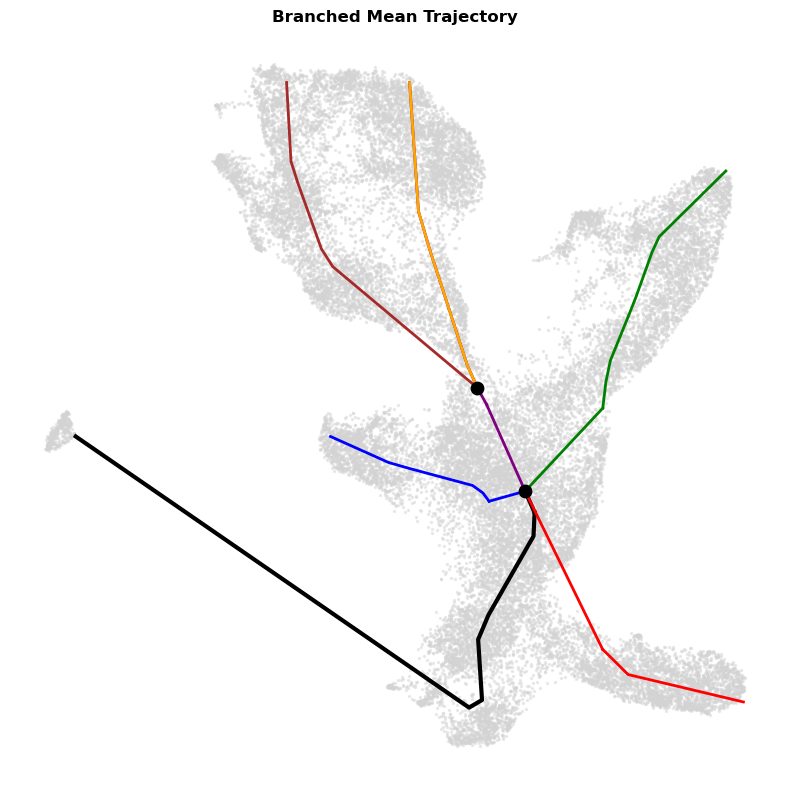

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# USER-DEFINED TREE TOPOLOGY
# =========================
branches = {
    "trunk": [0, 1, 2, 3, 4],
    "branch_1": [1],
    "branch_3": [3],
    "branch_4": [4],
    "branch_02": [0],
    "branch_0": [0],
    "branch_2": [2],
}

split_fracs = {
    "split1": 0.5,
    "split2": 0.7,
}

# =========================
# HELPERS
# =========================
def mean_traj_from_clusters(clusters):
    trajs = [np.asarray(smoothed_mean_trajs[cl]) for cl in clusters]
    min_len = min(len(t) for t in trajs)
    trajs = [t[:min_len] for t in trajs]
    return np.mean(trajs, axis=0)

def idx_from_frac(traj, frac):
    return int(frac * (len(traj) - 1))

# =========================
# BUILD SEGMENTS
# =========================
segments = {name: mean_traj_from_clusters(cls) for name, cls in branches.items()}

# =========================
# BRANCH POINTS
# =========================
i_split1 = idx_from_frac(segments["trunk"], split_fracs["split1"])
i_split2 = idx_from_frac(segments["branch_02"], split_fracs["split2"])

bp1 = segments["trunk"][i_split1]
bp2 = segments["branch_02"][i_split2]

# =========================
# PLOT
# =========================
connect_after_split = {
    "branch_1": i_split1 + 10,
    "branch_3": i_split1 + 5,
    "branch_4": i_split1 + 1,
    "branch_02": i_split1 + 5
}

fig, ax = plt.subplots(figsize=(8,8))

# background UMAP
ax.scatter(umap_points[:,0], umap_points[:,1], color='lightgrey', s=2, alpha=0.4)

# ---- trunk
trunk_seg = segments["trunk"][:i_split1]
ax.plot(trunk_seg[:,0], trunk_seg[:,1], c='black', lw=3)
# connect trunk to split point
ax.plot([trunk_seg[-1,0], bp1[0]], [trunk_seg[-1,1], bp1[1]], c='black', lw=3)

# ---- first split
for name, color in zip(["branch_1","branch_3","branch_4","branch_02"], ["red","blue","green","purple"]):
    seg = segments[name]
    if name in connect_after_split:
        connect_idx = connect_after_split[name]
        # link split point directly to the later index
        ax.plot([bp1[0], seg[connect_idx,0]], [bp1[1], seg[connect_idx,1]], c=color, lw=2)
        # continue with the rest of the branch
        ax.plot(seg[connect_idx:,0], seg[connect_idx:,1], c=color, lw=2)
    else:
        ax.plot([bp1[0]] + seg[i_split1:,0].tolist(),
                [bp1[1]] + seg[i_split1:,1].tolist(),
                c=color, lw=2)

# ---- second split
for name, color in zip(["branch_0","branch_2"], ["orange","brown"]):
    seg = segments[name]
    ax.plot([bp2[0]] + seg[i_split2:,0].tolist(),
            [bp2[1]] + seg[i_split2:,1].tolist(),
            c=color, lw=2)

# ---- branch points
ax.scatter(*bp1, c='k', s=80, zorder=5)
ax.scatter(*bp2, c='k', s=80, zorder=5)

ax.set_title("Branched Mean Trajectory", fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()


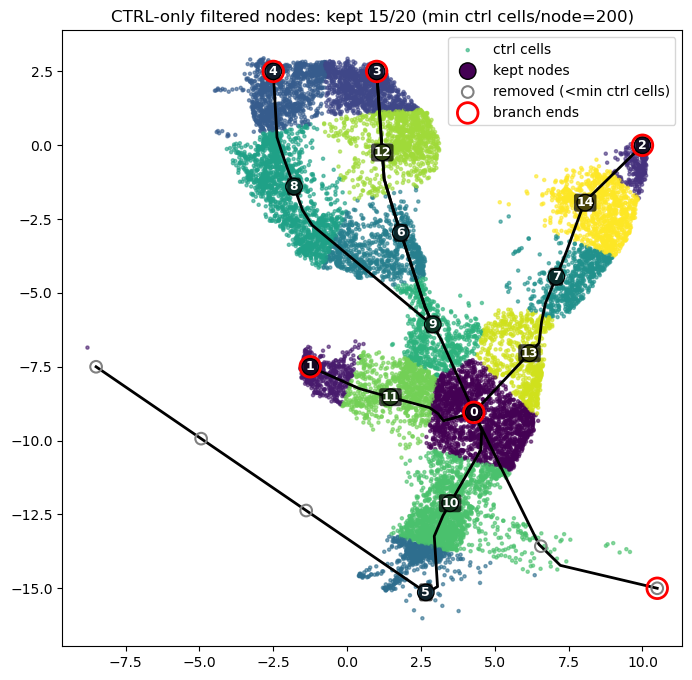

In [ ]:



# ---------------- CONFIG ----------------
N_NODES_TOTAL       = 20     
STRICT_TOTAL        = True   
TARGET_SPACING      = 0.12   
FORCE_TRUNK_END     = True   
CELL_X_COL          = "Z_space1"
CELL_Y_COL          = "Z_space2"
CONDITION_COL       = "Condition"   
CTRL_VALUE          = "ctrl"

MIN_CELLS_PER_NODE  = 200    
# ----------------------------------------

# =========================
# 0) BUILD POLYLINES
# =========================
polylines = []

# trunk 
trunk_poly = segments["trunk"][:i_split1 + 1]
polylines.append(("trunk", trunk_poly))

# first split children
for name in ["branch_1", "branch_3", "branch_4", "branch_02"]:
    seg = segments[name]
    if name in connect_after_split:
        ci = connect_after_split[name]
        poly = np.vstack([bp1, seg[ci:]])
    else:
        poly = np.vstack([bp1, seg[i_split1:]])
    polylines.append((name, poly))

# second split children
for name in ["branch_0", "branch_2"]:
    seg = segments[name]
    poly = np.vstack([bp2, seg[i_split2:]])
    polylines.append((name, poly))

# =========================
# 1) HELPERS
# =========================
def poly_arclength(P):
    if len(P) < 2:
        return np.array([0.0]), 0.0
    d = np.linalg.norm(P[1:] - P[:-1], axis=1)
    s = np.concatenate([[0.0], np.cumsum(d)])
    return s, float(s[-1])

def sample_poly_by_arclength(P, n_nodes, include_endpoint=True):
    """
    Evenly sample n_nodes along polyline P by arclength.
    If n_nodes == 1: returns endpoint (forces "go until end").
    """
    if n_nodes <= 0:
        return np.empty((0, 2))
    if n_nodes == 1:
        return P[-1:].copy()

    s, L = poly_arclength(P)
    if L == 0 or len(P) == 1:
        return np.repeat(P[-1:], n_nodes, axis=0)

    targets = np.linspace(0, L, n_nodes) if include_endpoint else np.linspace(0, L, n_nodes + 2)[1:-1]

    out = []
    j = 0
    for t in targets:
        while j < len(s) - 2 and s[j + 1] < t:
            j += 1
        segL = s[j + 1] - s[j]
        alpha = 0.0 if segL == 0 else (t - s[j]) / segL
        out.append((1 - alpha) * P[j] + alpha * P[j + 1])
    return np.asarray(out)

def dedup_points(points, tol=1e-10):
    if len(points) == 0:
        return points
    key = np.round(points / tol).astype(np.int64)
    _, idx = np.unique(key, axis=0, return_index=True)
    return points[np.sort(idx)]

def assign_cells_to_nodes(cells_xy, nodes_xy, chunk=50000):
    """
    Returns assigned_node (N,) and assigned_dist (N,).
    Chunked to avoid huge memory for big N.
    """
    N = cells_xy.shape[0]
    assigned = np.empty(N, dtype=int)
    mind = np.empty(N, dtype=float)
    for i0 in range(0, N, chunk):
        i1 = min(N, i0 + chunk)
        P = cells_xy[i0:i1]
        d = np.linalg.norm(P[:, None, :] - nodes_xy[None, :, :], axis=2)
        j = np.argmin(d, axis=1)
        assigned[i0:i1] = j
        mind[i0:i1] = d[np.arange(i1 - i0), j]
    return assigned, mind

def filter_nodes_by_cellcount(nodes_xy, assigned_node, min_cells):
    """
    Keep only nodes with >= min_cells assigned.
    Returns:
      keep_mask (M,), old_to_new map (M,), new_nodes_xy, counts
    """
    M = nodes_xy.shape[0]
    counts = np.bincount(assigned_node, minlength=M)

    keep_mask = counts >= min_cells
    if not np.any(keep_mask):
        # If nothing passes, keep the single most-populated node
        keep_mask[np.argmax(counts)] = True

    kept_idx = np.where(keep_mask)[0]
    new_nodes_xy = nodes_xy[kept_idx]

    old_to_new = -np.ones(M, dtype=int)
    old_to_new[kept_idx] = np.arange(len(kept_idx))

    return keep_mask, old_to_new, new_nodes_xy, counts

# =========================
# 2) FORCED ENDPOINTS 
# =========================
forced_endpoints = []
for bname, P in polylines:
    if (bname == "trunk") and (not FORCE_TRUNK_END):
        continue
    forced_endpoints.append(P[-1])
forced_endpoints = dedup_points(np.vstack(forced_endpoints) if len(forced_endpoints) else np.empty((0, 2)))

# =========================
# 3) NODE PLACEMENT 
# =========================
if STRICT_TOTAL:
    step = max(1e-6, TARGET_SPACING / 2.0)
    candidates = []
    for _, P in polylines:
        s, L = poly_arclength(P)
        if L == 0:
            candidates.append(P[-1:])
            continue
        n_c = max(2, int(np.ceil(L / step)) + 1)
        candidates.append(sample_poly_by_arclength(P, n_c, include_endpoint=True))
    candidates = dedup_points(np.vstack(candidates))

    selected = forced_endpoints.copy()

    if len(selected) > N_NODES_TOTAL:
        sel = [selected[0]]
        min_d2 = np.sum((selected - sel[0])**2, axis=1)
        while len(sel) < N_NODES_TOTAL:
            j = int(np.argmax(min_d2))
            sel.append(selected[j])
            d2_new = np.sum((selected - selected[j])**2, axis=1)
            min_d2 = np.minimum(min_d2, d2_new)
        nodes_xy = np.asarray(sel)
    else:
        if len(selected) == 0:
            selected = candidates[:1].copy()

        diff = candidates[:, None, :] - selected[None, :, :]
        min_d2 = np.min(np.sum(diff * diff, axis=2), axis=1)

        while len(selected) < N_NODES_TOTAL:
            j = int(np.argmax(min_d2))
            newp = candidates[j]
            selected = np.vstack([selected, newp])
            d2_new = np.sum((candidates - newp) ** 2, axis=1)
            min_d2 = np.minimum(min_d2, d2_new)

        nodes_xy = dedup_points(selected)

        if len(nodes_xy) < N_NODES_TOTAL:
            diff = candidates[:, None, :] - nodes_xy[None, :, :]
            min_d2 = np.min(np.sum(diff * diff, axis=2), axis=1)
            while len(nodes_xy) < N_NODES_TOTAL:
                j = int(np.argmax(min_d2))
                nodes_xy = dedup_points(np.vstack([nodes_xy, candidates[j]]))
                diff = candidates[:, None, :] - nodes_xy[None, :, :]
                min_d2 = np.min(np.sum(diff * diff, axis=2), axis=1)

        if len(nodes_xy) > N_NODES_TOTAL:
            nodes_xy = nodes_xy[:N_NODES_TOTAL]

else:
    nodes = []
    for bname, P in polylines:
        s, L = poly_arclength(P)
        if (bname == "trunk") and (not FORCE_TRUNK_END):
            n_b = max(2, int(np.round(L / TARGET_SPACING)) + 1) if L > 0 else 0
            pts = sample_poly_by_arclength(P, n_b, include_endpoint=True) if n_b > 0 else np.empty((0,2))
            nodes.append(pts)
        else:
            n_b = 1 if L < TARGET_SPACING else (int(np.round(L / TARGET_SPACING)) + 1)
            n_b = max(1, n_b)
            pts = sample_poly_by_arclength(P, n_b, include_endpoint=True)
            nodes.append(pts)
    nodes_xy = dedup_points(np.vstack(nodes) if len(nodes) else np.empty((0,2)))

# =========================
# 4) ASSIGN CTRL CELLS -> NODES
# =========================
ctrl_mask = df[CONDITION_COL].eq(CTRL_VALUE) & (df["Time_int"] > 48)
cells_xy = df.loc[ctrl_mask, [CELL_X_COL, CELL_Y_COL]].to_numpy()

assigned_node, assigned_dist = assign_cells_to_nodes(cells_xy, nodes_xy)

# =========================
# 5) FILTER NODES BY CTRL CELL COUNT, THEN REASSIGN CTRL CELLS
# =========================
keep_mask, old_to_new, nodes_xy_filt, counts = filter_nodes_by_cellcount(
    nodes_xy, assigned_node, MIN_CELLS_PER_NODE
)

assigned_node_filt, assigned_dist_filt = assign_cells_to_nodes(cells_xy, nodes_xy_filt)

# =========================
# 6) PLOT 
# =========================
plt.figure(figsize=(8, 8))

# tree in black
for bname, P in polylines:
    plt.plot(P[:, 0], P[:, 1], lw=2, c="k")

# ctrl cells coloured by assigned node (filtered)
plt.scatter(
    cells_xy[:, 0], cells_xy[:, 1],
    c=assigned_node_filt, cmap=plt.cm.viridis,
    s=5, alpha=0.6, zorder=1, label="ctrl cells"
)

# node ID labels
for i, (x, y) in enumerate(nodes_xy_filt):
    plt.text(
        x, y, str(i),
        fontsize=9, fontweight="bold",
        ha="center", va="center", color="white",
        zorder=6,
        bbox=dict(boxstyle="round,pad=0.2", fc="black", ec="none", alpha=0.7)
    )

# nodes kept
plt.scatter(
    nodes_xy_filt[:, 0], nodes_xy_filt[:, 1],
    c=np.arange(len(nodes_xy_filt)), cmap=plt.cm.viridis,
    s=140, edgecolor="k", zorder=5, label="kept nodes"
)

# removed nodes lightly (optional)
removed = nodes_xy[~keep_mask]
if len(removed):
    plt.scatter(
        removed[:, 0], removed[:, 1],
        s=70, facecolors="none", edgecolors="grey", lw=1.5,
        zorder=4, label="removed (<min ctrl cells)"
    )

# highlight forced ends (for reference)
if len(forced_endpoints):
    plt.scatter(
        forced_endpoints[:, 0], forced_endpoints[:, 1],
        s=220, facecolors="none", edgecolors="red", lw=2,
        zorder=6, label="branch ends"
    )

plt.axis("equal")
plt.title(
    f"CTRL-only filtered nodes: kept {len(nodes_xy_filt)}/{len(nodes_xy)} "
    f"(min ctrl cells/node={MIN_CELLS_PER_NODE})"
)
plt.legend()
plt.show()


## Manually keeping nodes

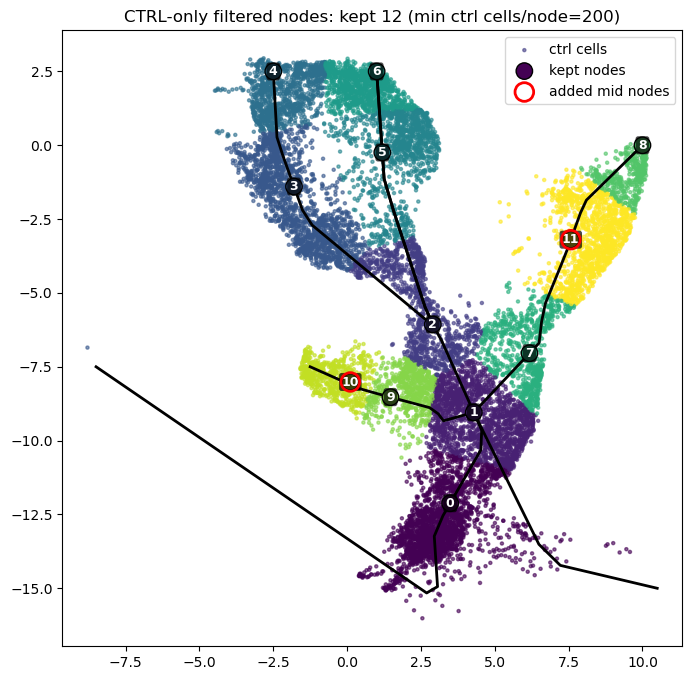

In [ ]:

# IDs of nodes to keep 
keep_ids = [10, 0, 9, 8, 4, 12, 3, 13, 2, 11]

# Grab coordinates of kept nodes
nodes_xy_custom = nodes_xy_filt[keep_ids]

# Now, add nodes in the middle of 11-1 and 7-14
# Find original coordinates for nodes 11, 1, 7, 14
coord_11 = nodes_xy_filt[11]
coord_1  = nodes_xy_filt[1]
coord_7  = nodes_xy_filt[7]
coord_14 = nodes_xy_filt[14]

# Middle points
mid_11_1 = 0.5 * (coord_11 + coord_1)
mid_7_14 = 0.5 * (coord_7 + coord_14)

# Append new nodes
nodes_xy_custom = np.vstack([nodes_xy_custom, mid_11_1, mid_7_14])

# Reassign filtered nodes
nodes_xy_filt = nodes_xy_custom

# Reassign ctrl cells to new custom nodes
assigned_node_filt, assigned_dist_filt = assign_cells_to_nodes(cells_xy, nodes_xy_filt)

# =========================
# 6) PLOT 
# =========================
plt.figure(figsize=(8, 8))

# tree in black
for bname, P in polylines:
    plt.plot(P[:, 0], P[:, 1], lw=2, c="k")

# ctrl cells coloured by assigned node (filtered)
plt.scatter(
    cells_xy[:, 0], cells_xy[:, 1],
    c=assigned_node_filt, cmap=plt.cm.viridis,
    s=5, alpha=0.6, zorder=1, label="ctrl cells"
)

# node ID labels
for i, (x, y) in enumerate(nodes_xy_filt):
    plt.text(
        x, y, str(i),
        fontsize=9, fontweight="bold",
        ha="center", va="center", color="white",
        zorder=6,
        bbox=dict(boxstyle="round,pad=0.2", fc="black", ec="none", alpha=0.7)
    )

# nodes kept
plt.scatter(
    nodes_xy_filt[:, 0], nodes_xy_filt[:, 1],
    c=np.arange(len(nodes_xy_filt)), cmap=plt.cm.viridis,
    s=140, edgecolor="k", zorder=5, label="kept nodes"
)


new_nodes_idx = [-2, -1]  
plt.scatter(
    nodes_xy_filt[new_nodes_idx, 0], nodes_xy_filt[new_nodes_idx, 1],
    s=180, facecolors="none", edgecolors="red", lw=2, zorder=7, label="added mid nodes"
)

plt.axis("equal")
plt.title(
    f"CTRL-only filtered nodes: kept {len(nodes_xy_filt)} "
    f"(min ctrl cells/node={MIN_CELLS_PER_NODE})"
)
plt.legend()
plt.show()


## Save trajectories

In [33]:
import numpy as np

poly_names = [name for name, _ in polylines]
poly_coords = [P for _, P in polylines]

np.savez(
    "trajectory_ctrl_nodes.npz",

    # nodes
    nodes_xy_filt=nodes_xy_filt,
    nodes_xy_all=nodes_xy,
    forced_endpoints=forced_endpoints,

    # bookkeeping
    keep_mask=keep_mask,
    old_to_new=old_to_new,
    counts=counts,
    assigned_node_filt=assigned_node_filt,

    # polylines (SAFE)
    poly_names=np.array(poly_names),
    poly_lengths=np.array([len(P) for P in poly_coords]),
    poly_coords=np.vstack(poly_coords),
)


In [34]:
df_ctrl = df.loc[ctrl_mask]

In [35]:
# node IDs
node_id = np.arange(nodes_xy_filt.shape[0], dtype=int)
df_ctrl["node_id"] = assigned_node_filt.astype(int)



/tmp/ipykernel_1732328/242496224.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ctrl["node_id"] = assigned_node_filt.astype(int)


In [37]:
df_ctrl.to_csv('INPUT/scRNAseq/Trajectory_node_assignement.csv')

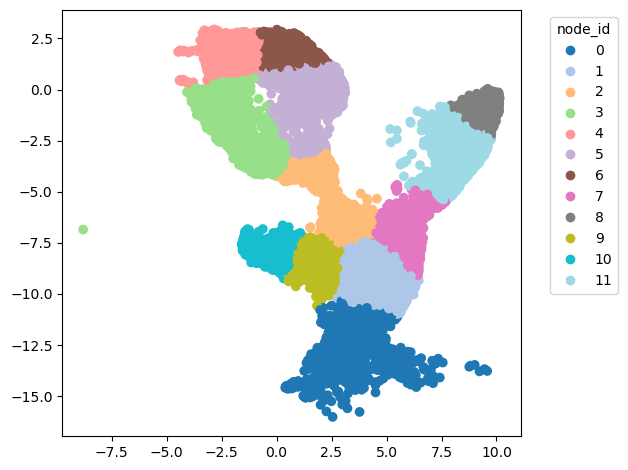

In [38]:
import matplotlib.pyplot as plt
import numpy as np

sc = plt.scatter(
    df_ctrl["Z_space1"],
    df_ctrl["Z_space2"],
    c=df_ctrl["node_id"],
    cmap="tab20"
)

# build legend
handles, _ = sc.legend_elements(prop="colors", alpha=1)
labels = np.unique(df_ctrl["node_id"])

plt.legend(handles, labels, title="node_id", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()
